# A5 — Paired Review-vs-Sentence Significance Test
**Group:** Flower | **Author:** Sam (st127012)

For each shared (model × aggregation) variant, we compare per-query nDCG@10 at
**review level** versus **sentence level** using a two-sided paired randomisation
test (10 000 permutations) with Holm-Bonferroni correction.

This directly answers: *does switching the retrieval unit from review to sentence
produce a significant, consistent change in ranking quality?*

Inputs (gitignored, local only):
- `baselines/cache/sentence/per_query_sentence.csv`
- `baselines/cache/review/per_query_review.csv`  *(or `baselines/cache/per_query_review.csv`)*


## 0. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

HERE  = Path.cwd()
ROOT  = HERE if (HERE / "datasets").exists() else HERE.parent
CACHE = ROOT / "baselines" / "cache"

# per_query CSVs may live in cache/sentence/ or cache/ depending on run
def _load_pq(unit: str) -> pd.DataFrame:
    candidates = [
        CACHE / unit / f"per_query_{unit}.csv",
        CACHE / f"per_query_{unit}.csv",
    ]
    for p in candidates:
        if p.exists():
            print(f"  Loaded: {p}")
            return pd.read_csv(p)
    raise FileNotFoundError(f"per_query_{unit}.csv not found in {CACHE}")

pq_rev = _load_pq("review")
pq_sen = _load_pq("sentence")

print(f"Review rows:   {len(pq_rev)}  | models: {pq_rev['Model'].nunique()}")
print(f"Sentence rows: {len(pq_sen)}  | models: {pq_sen['Model'].nunique()}")
pq_rev.head(3)


  Loaded: /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/review/per_query_review.csv
  Loaded: /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/sentence/per_query_sentence.csv
Review rows:   1500  | models: 15
Sentence rows: 1500  | models: 15


,Model,query,MAP,MRR,nDCG@5,nDCG@10,Recall@5,Recall@10,P@5,P@10
0,BM25 | max,A bar with a patio,0.871749,1.000000,0.819651,0.868784,0.571429,0.857143,0.8,0.6
1,BM25 | max,A bar with good music and reasonably priced beer,0.231462,0.250000,0.372963,0.491607,0.166667,0.500000,0.2,0.3
2,BM25 | max,A cafe that also offers beer,0.111111,0.111111,0.072401,0.315798,0.000000,1.000000,0.0,0.1


## 1. Find Shared (Model, Query) Pairs

Both CSVs use a `Model` column like `"Dense | top-10 mean"`.
We inner-join on `(Model, query)` to ensure we only compare runs that exist
in both unit types and over the same queries.


In [2]:
METRIC = "nDCG@10"

merged = pd.merge(
    pq_rev[["Model", "query", METRIC]].rename(columns={METRIC: "review"}),
    pq_sen[["Model", "query", METRIC]].rename(columns={METRIC: "sentence"}),
    on=["Model", "query"],
    how="inner",
)
merged["diff"] = merged["sentence"] - merged["review"]  # positive = sentence better

shared_models = sorted(merged["Model"].unique())
print(f"Shared variants: {len(shared_models)}")
print(f"Queries per variant: {merged.groupby('Model').size().unique()}")
merged.head(5)


Shared variants: 15
Queries per variant: [100]


,Model,query,review,sentence,diff
0,BM25 | max,A bar with a patio,0.868784,0.663593,-0.205191
1,BM25 | max,A bar with good music and reasonably priced beer,0.491607,0.489797,-0.001810
2,BM25 | max,A cafe that also offers beer,0.315798,0.419710,0.103912
3,BM25 | max,A date place for valentines with affordable dr...,0.622525,0.640719,0.018194
4,BM25 | max,A fancy place with an outdoor setting for a ro...,0.616370,0.760342,0.143972


## 2. Paired Randomisation Test (Two-sided, 10 000 permutations)

For each model variant:
- Observed statistic: mean(sentence_nDCG@10 − review_nDCG@10)
- Null distribution: randomly flip signs on each paired difference 10 000 times
- p-value: fraction of |null means| ≥ |observed mean|
- Apply Holm-Bonferroni correction across variants


In [3]:
RNG = np.random.default_rng(42)
N_PERM = 10_000

def paired_rand_test(diffs: np.ndarray, n_perm: int = N_PERM) -> float:
    """Two-sided paired randomisation test. Returns raw p-value."""
    obs = np.abs(np.mean(diffs))
    signs = RNG.choice([-1, 1], size=(n_perm, len(diffs)))
    null_means = np.abs((signs * diffs).mean(axis=1))
    return float((null_means >= obs).mean())

def holm_correction(p_values: list) -> list:
    """Holm-Bonferroni correction. Returns adjusted p-values."""
    n = len(p_values)
    order = np.argsort(p_values)
    adj = np.zeros(n)
    running_max = 0.0
    for rank, idx in enumerate(order):
        corrected = (n - rank) * p_values[idx]
        running_max = max(running_max, corrected)
        adj[idx] = min(running_max, 1.0)
    return adj.tolist()

rows = []
for model, grp in merged.groupby("Model"):
    diffs = grp["diff"].values
    n = len(diffs)
    mean_diff = diffs.mean()
    se = diffs.std(ddof=1) / np.sqrt(n)
    raw_p = paired_rand_test(diffs)
    rows.append({
        "Model": model,
        "n_queries": n,
        f"mean_sent_{METRIC}": grp["sentence"].mean(),
        f"mean_rev_{METRIC}": grp["review"].mean(),
        "mean_diff (sent−rev)": mean_diff,
        "SE": se,
        "p_raw": raw_p,
    })

results_df = pd.DataFrame(rows)
results_df["p_holm"] = holm_correction(results_df["p_raw"].tolist())
results_df["sig*"] = results_df["p_holm"].apply(lambda p: "***" if p < 0.001 else
                                                             "**"  if p < 0.01  else
                                                             "*"   if p < 0.05  else "")
results_df = results_df.sort_values("mean_diff (sent−rev)", ascending=False)
print(results_df.to_string(index=False))


                     Model  n_queries  mean_sent_nDCG@10  mean_rev_nDCG@10  mean_diff (sent−rev)       SE  p_raw  p_holm sig*
       Dense | top-10 mean        100           0.681547          0.668240              0.013308 0.010527 0.2102  1.0000     
        Dense | top-5 mean        100           0.673254          0.667620              0.005634 0.011261 0.6131  1.0000     
    BM25 | concat doc (v1)        100           0.621070          0.621070              0.000000 0.000000 1.0000  1.0000     
          Popularity (LOO)        100           0.484039          0.484039              0.000000 0.000000 1.0000  1.0000     
         Random (expected)        100           0.347819          0.347819              0.000000 0.000000 1.0000  1.0000     
              Review count        100           0.373530          0.373530              0.000000 0.000000 1.0000  1.0000     
               BM25 | mean        100           0.547874          0.548718             -0.000844 0.012238 0.9459  1.00

## 3. Bootstrap 95% Confidence Intervals on Mean Difference

CI on mean(sentence − review) nDCG@10 across queries (2 500 bootstrap resamples).


In [4]:
N_BOOT = 2500

ci_rows = []
for model, grp in merged.groupby("Model"):
    diffs = grp["diff"].values
    boot_means = [RNG.choice(diffs, size=len(diffs), replace=True).mean()
                  for _ in range(N_BOOT)]
    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    ci_rows.append({"Model": model, "CI_lo": lo, "CI_hi": hi})

ci_df = pd.DataFrame(ci_rows)
results_df = results_df.merge(ci_df, on="Model")

cols_show = ["Model", f"mean_sent_{METRIC}", f"mean_rev_{METRIC}",
             "mean_diff (sent−rev)", "CI_lo", "CI_hi", "p_raw", "p_holm", "sig*"]
print(results_df[cols_show].round(4).to_string(index=False))


                     Model  mean_sent_nDCG@10  mean_rev_nDCG@10  mean_diff (sent−rev)   CI_lo   CI_hi  p_raw  p_holm sig*
       Dense | top-10 mean             0.6815            0.6682                0.0133 -0.0068  0.0340 0.2102  1.0000     
        Dense | top-5 mean             0.6733            0.6676                0.0056 -0.0153  0.0281 0.6131  1.0000     
    BM25 | concat doc (v1)             0.6211            0.6211                0.0000  0.0000  0.0000 1.0000  1.0000     
          Popularity (LOO)             0.4840            0.4840                0.0000  0.0000  0.0000 1.0000  1.0000     
         Random (expected)             0.3478            0.3478                0.0000  0.0000  0.0000 1.0000  1.0000     
              Review count             0.3735            0.3735                0.0000  0.0000  0.0000 1.0000  1.0000     
               BM25 | mean             0.5479            0.5487               -0.0008 -0.0244  0.0234 0.9459  1.0000     
        Dense | top-3 me

## 4. Save Results Table

In [5]:
OUT = CACHE / "a5_review_vs_sentence_test.csv"
results_df[cols_show].round(4).to_csv(OUT, index=False)
print(f"Saved → {OUT}")


Saved → /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/a5_review_vs_sentence_test.csv


## 5. Forest Plot — Mean Difference (Sentence − Review) nDCG@10

Each row is one (model × aggregation) variant. A vertical dashed line at 0 marks
no change. Error bars show bootstrap 95% CIs. Significant variants (Holm p < 0.05)
are shown in blue; non-significant in grey.


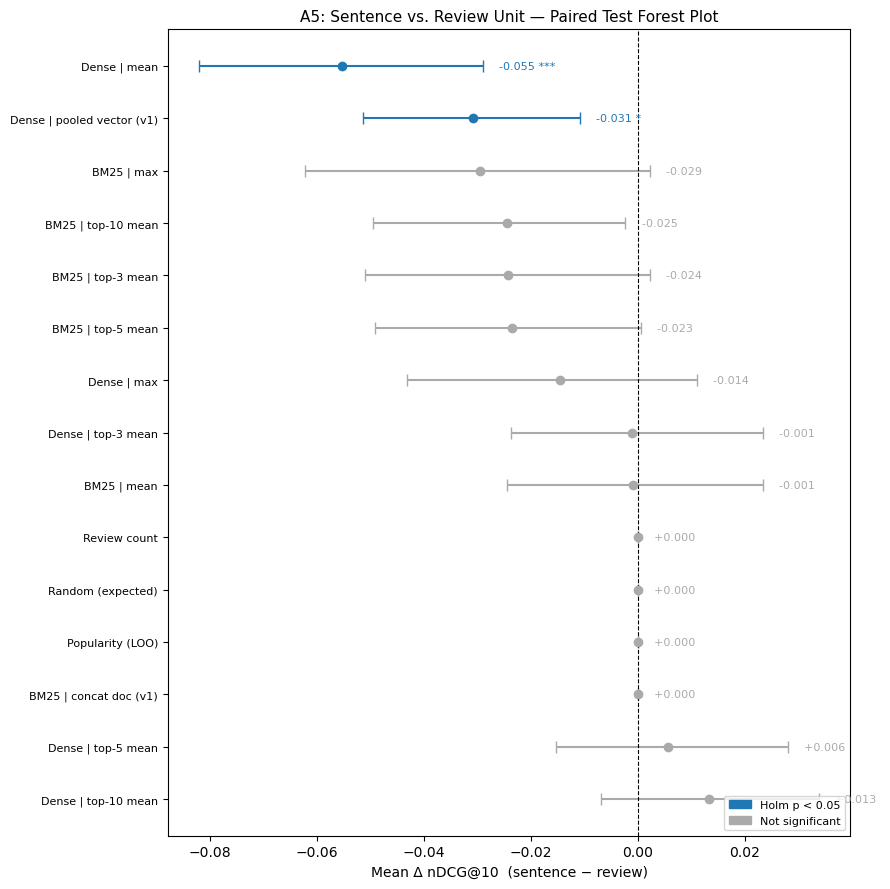

Saved → a5_forest_plot.png


In [6]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(results_df) + 1.5))

for i, row in results_df.reset_index(drop=True).iterrows():
    sig = row["p_holm"] < 0.05
    color = "#1f77b4" if sig else "#aaaaaa"
    label_suffix = row["sig*"]
    ax.errorbar(
        x=row["mean_diff (sent−rev)"],
        y=i,
        xerr=[[row["mean_diff (sent−rev)"] - row["CI_lo"]],
              [row["CI_hi"] - row["mean_diff (sent−rev)"]]],
        fmt="o", color=color, capsize=4, linewidth=1.5, markersize=6,
    )
    ax.text(
        x=row["CI_hi"] + 0.003,
        y=i,
        s=f"{row['mean_diff (sent−rev)']:+.3f} {label_suffix}",
        va="center", fontsize=8, color=color,
    )

ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_yticks(range(len(results_df)))
ax.set_yticklabels(results_df["Model"].tolist(), fontsize=8)
ax.set_xlabel(f"Mean Δ {METRIC}  (sentence − review)", fontsize=10)
ax.set_title("A5: Sentence vs. Review Unit — Paired Test Forest Plot", fontsize=11)

sig_patch   = mpatches.Patch(color="#1f77b4", label="Holm p < 0.05")
insig_patch = mpatches.Patch(color="#aaaaaa", label="Not significant")
ax.legend(handles=[sig_patch, insig_patch], fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig(CACHE / "a5_forest_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → a5_forest_plot.png")


## 6. Summary

Print a concise paragraph suitable for the final report.


In [7]:
sig_better  = results_df[(results_df["mean_diff (sent−rev)"] > 0) & (results_df["p_holm"] < 0.05)]
sig_worse   = results_df[(results_df["mean_diff (sent−rev)"] < 0) & (results_df["p_holm"] < 0.05)]
insig       = results_df[results_df["p_holm"] >= 0.05]

print(f"Total variants compared: {len(results_df)}")
print(f"  Sentence significantly BETTER (Holm p<0.05): {len(sig_better)}")
print(f"    → {sig_better['Model'].tolist()}")
print(f"  Sentence significantly WORSE  (Holm p<0.05): {len(sig_worse)}")
print(f"    → {sig_worse['Model'].tolist()}")
print(f"  No significant difference: {len(insig)}")
print()

best = results_df.iloc[0]
worst = results_df.iloc[-1]
print(f"Largest gain : {best['Model']}  Δ={best['mean_diff (sent−rev)']:+.3f}  "
      f"[{best['CI_lo']:+.3f}, {best['CI_hi']:+.3f}]  Holm p={best['p_holm']:.4f}")
print(f"Largest loss : {worst['Model']}  Δ={worst['mean_diff (sent−rev)']:+.3f}  "
      f"[{worst['CI_lo']:+.3f}, {worst['CI_hi']:+.3f}]  Holm p={worst['p_holm']:.4f}")


Total variants compared: 15
  Sentence significantly BETTER (Holm p<0.05): 0
    → []
  Sentence significantly WORSE  (Holm p<0.05): 2
    → ['Dense | pooled vector (v1)', 'Dense | mean']
  No significant difference: 13

Largest gain : Dense | top-10 mean  Δ=+0.013  [-0.007, +0.034]  Holm p=1.0000
Largest loss : Dense | mean  Δ=-0.055  [-0.082, -0.029]  Holm p=0.0000
